# Initial exploratory data analysis

The idea here is to see in more details what was recorded, how usable each features are, and find some basic statistics of the dataset in order to have a better overview before doing feature analysis and more complex data preprocessing.

We will compare our data with published numbers and hope that both match. Note that the results of their study, which focused on a binary classification (conscious vs. unconscious) will not be relevant for our study which will be oriented on a time-to-awakening prediction.

In [1]:
import ast
import matplotlib.pyplot as plt
import pandas as pd 
from IPython.display import display
from glob import glob
from pathlib import Path
from lifelines import KaplanMeierFitter

## 1. Dataset features and comparisons

We first display the feature names of the `raw` dataset, which contains most of the information we will be needing for our study, and compare our metadata values with the ones stated in [their publication](https://arxiv.org/pdf/2607.02570).

In [2]:
# 1. Show the column names from one raw recording.
raw = pd.read_csv("../../data/raw/10-003.csv", nrows=0)

display(pd.DataFrame({"raw columns": raw.columns}))

# 2. Compare published figures with local metadata.
# The first CSV column contains recording IDs.
metadata = pd.read_csv(
    "../../data/metadata/DOSE-I_metadata.csv",
    index_col=0,
)

comparison = pd.DataFrame({
    "measure": [
        "Recordings",
        "Total recording duration",
        "Endoscopic procedures",
        "Consciousness transitions",
        "Sedation assessments",
    ],
    "published": [171, 78.5, 281, 1129, 7328],
    "local_metadata": [
        len(metadata),
        metadata["length"].sum() / 3600,
        metadata["endoscopies"].sum(),
        metadata["SOC_trans"].sum(),
        metadata["MOAAS_sum"].sum(),
    ],
    "unit": ["count", "hours", "count", "count", "count"],
})

comparison["difference"] = (
    comparison["local_metadata"] - comparison["published"]
)

display(comparison.set_index("measure").round(3))

,raw columns
0,Time
1,Intellivue/ECG_II
2,Intellivue/EEG_1
3,Intellivue/EEG_2
4,Intellivue/PLETH
5,Intellivue/RESP
6,Intellivue/ECG_HR
7,Intellivue/RR
8,Intellivue/PLETH_SAT_O2
9,Intellivue/PLETH_HR


,published,local_metadata,unit,difference
measure,,,,
Recordings,171.0,171.000,count,0.000
Total recording duration,78.5,78.622,hours,0.122
Endoscopic procedures,281.0,283.000,count,2.000
Consciousness transitions,1129.0,1132.000,count,3.000
Sedation assessments,7328.0,7345.000,count,17.000


We can note a slight difference between local metadata and published numbers, but not significant enough to alarm us. This probably comes from different dataset versions between the publication date and our study.

We will take a closer look at the distributions of these measures later on in the notebook.

## 2. Recording and population distributions



,count,mean,std,min,25%,50%,75%,max,missing
age,171.0,60.40,15.48,21.00,50.00,62.00,74.00,83.00,0
height,171.0,170.54,9.60,140.00,164.00,170.00,177.00,194.00,0
weight,171.0,79.01,19.45,34.00,65.00,77.00,90.00,165.00,0
bmi,171.0,27.10,6.19,13.79,22.97,25.95,30.08,62.87,0
recording_minutes,171.0,27.59,11.66,6.65,18.89,26.03,33.67,70.83,0


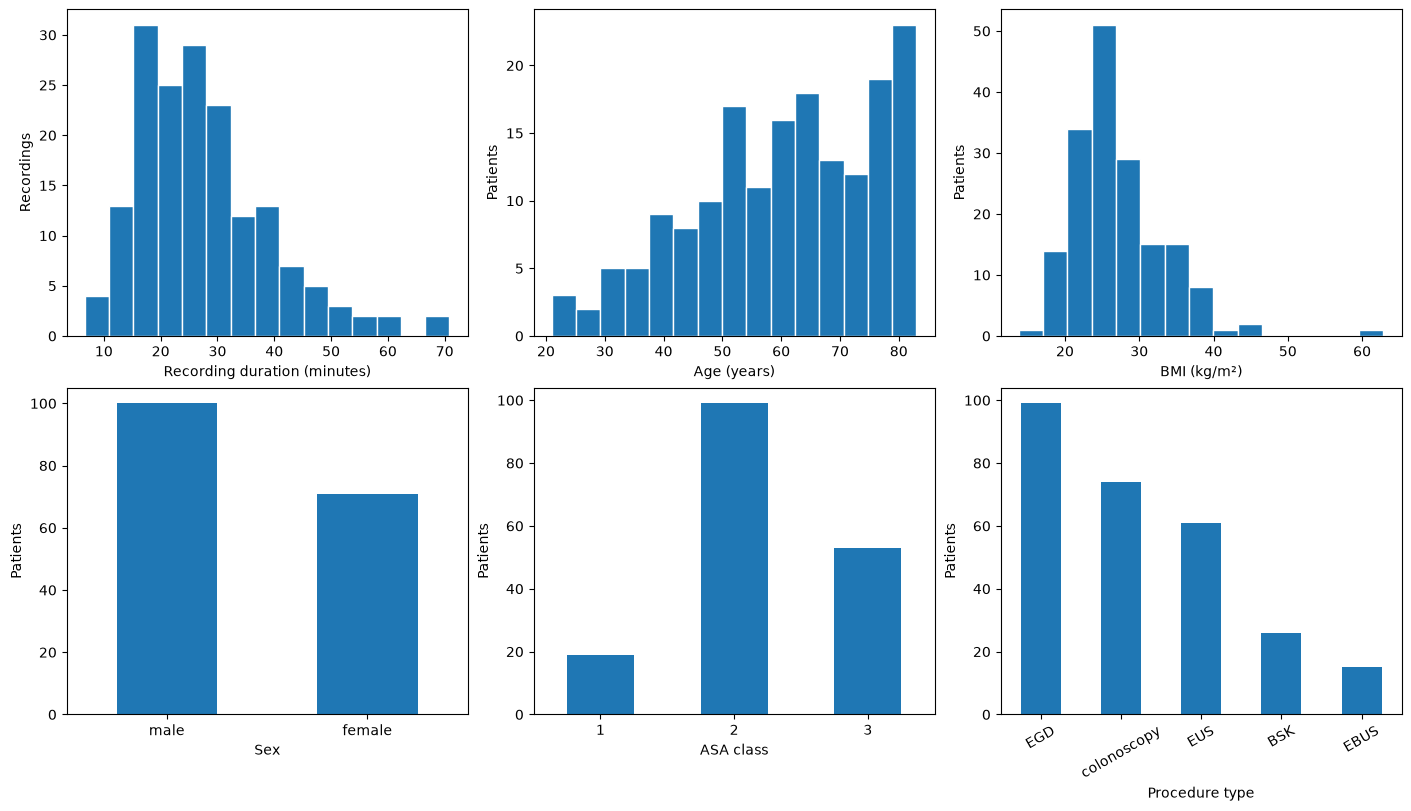

In [3]:

static = pd.read_csv(
    "../../data/static/DOSE-I_static_data.csv",
    index_col="ID",
)

# Summary table for continuous numerical features.
# Join by patient ID, rather than assuming the rows have the same order.
numerical = static[["age", "height", "weight", "bmi"]].copy()
numerical["recording_minutes"] = metadata["length"] / 60

summary = numerical.describe().T
summary["missing"] = numerical.isna().sum()

display(summary.round(2))

# Procedure types are stored as strings such as "['EGD', 'EUS']".
# Convert them to lists, then count each procedure separately.
procedures = static["endoscopy_type"].dropna().apply(ast.literal_eval)
procedure_counts = procedures.explode().value_counts()

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8),
    constrained_layout=True,
)

# Histograms for continuous variables.
axes[0, 0].hist(
    numerical["recording_minutes"].dropna(),
    bins=15, edgecolor="white",
)
axes[0, 0].set(xlabel="Recording duration (minutes)", ylabel="Recordings")

axes[0, 1].hist(
    numerical["age"].dropna(),
    bins=15, edgecolor="white",
)
axes[0, 1].set(xlabel="Age (years)", ylabel="Patients")

axes[0, 2].hist(
    numerical["bmi"].dropna(),
    bins=15, edgecolor="white",
)
axes[0, 2].set(xlabel="BMI (kg/m²)", ylabel="Patients")

# Bar charts for categorical variables.
static["sex"].fillna("Missing").value_counts().plot.bar(ax=axes[1, 0])
axes[1, 0].set(xlabel="Sex", ylabel="Patients")
axes[1, 0].tick_params(axis="x", rotation=0)

static["ASA"].value_counts().sort_index().plot.bar(ax=axes[1, 1])
axes[1, 1].set(xlabel="ASA class", ylabel="Patients")
axes[1, 1].tick_params(axis="x", rotation=0)

procedure_counts.plot.bar(ax=axes[1, 2])
axes[1, 2].set(xlabel="Procedure type", ylabel="Patients")
axes[1, 2].tick_params(axis="x", rotation=30)

plt.show()

### Important to notice
- __Recording duration__: It is interesting to point out that with mean 27.6 and median 26.0 close together, we have most of our recordings during around half an hour. The fact that 75% of the recordings are smaller than 34 minutes confirms this approximation. 
- __Age__: Since the dataset comes from real procedures, it is not that surprising to see that we have a quite old distribution: only 25% of the patients are younger than 50 years old. Our average patient is around 60 years old, and there are quite a few patients older than 75.
- __Sex__: Although the plot might show a significant difference between male and female in our records, percentage wise it is more balanced: Out of 171 recordings, we have 71 recordings coming from female patients (42%) and 100 from male patients (58%). We will still take this into account in our conclusions, as our model may be biased and more accurate for male data. We will probably note this in our ethics canvas that will be in the report of our results.
- __ASA class__: ASA is a "health score" defined as follows:
    <p align="center">
    <img src="ASA-score.png" width="500" alt="Similarity Tree">
    </p>
    coming from Kannan, T. (2017). ASA Grading: A Step Forward. Journal of Perioperative Practice, 27, 54 - 59.

    First we can see that we don't have any patient with a ASA score $\geq$ IV. Given the definitions, we might suppose that it is not usual to have a score that high, but it is still important to note that our model might fail predicting well for patients with _severe systemic diseases_.

    The examples from scores II and III confirm our __BMI__ data that suppose patients with BMI in the range $[30, 40]$ (II) or $> 40$ (III). Indeed, 25% of our recordings comes from patients with BMI $\geq 30$.

## 3. Data availability - EEG artifacts

Let's take a look at these EEG artifacts and to what extent the EEG data is representative/usable or not.

,count,mean,std,min,25%,50%,75%,max
epochs,171.0,827.982,350.107,201.000,556.00,781.000,1011.000,2126.000
annotated_seconds,171.0,1655.965,700.215,402.000,1112.00,1562.000,2022.000,4252.000
artifact_seconds,171.0,304.058,202.701,32.000,156.00,242.000,382.000,946.000
artifact_fraction,171.0,0.194,0.119,0.019,0.11,0.157,0.265,0.574


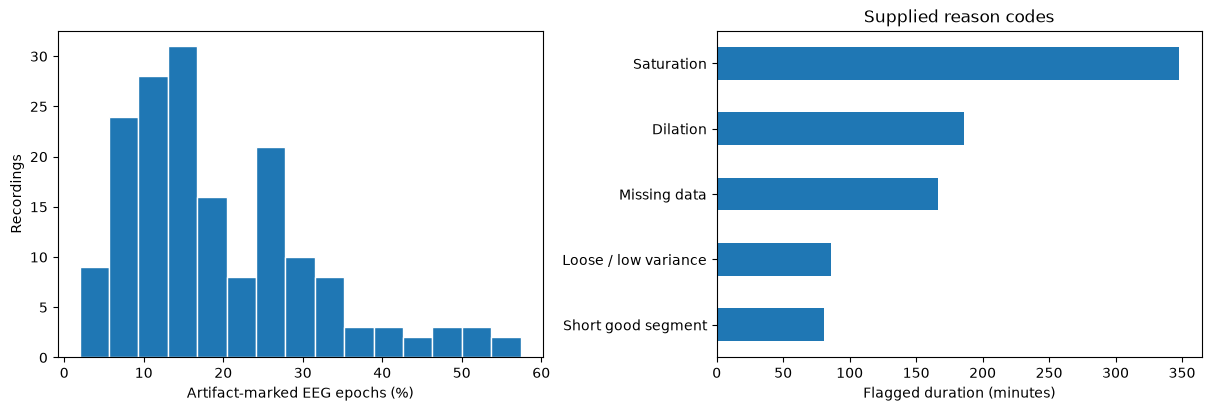

In [4]:
artifact_rows = []
artifact_reasons = []

for file in sorted(glob("../../data/artifacts/artifacts/*_artifacts.csv")):
    artifacts = pd.read_csv(file)

    # Duration of each annotated epoch, in seconds.
    duration = (
        pd.to_datetime(artifacts["end_idx"])
        - pd.to_datetime(artifacts["begin_idx"])
    ).dt.total_seconds()

    marked = artifacts["is_artifact"] == True

    artifact_rows.append({
        "epochs": len(artifacts),
        "annotated_seconds": duration.sum(),
        "artifact_seconds": duration[marked].sum(),
        "artifact_fraction": duration[marked].sum() / duration.sum(),
    })

    # Flagged duration grouped by reason for this recording.
    artifact_reasons.append(
        duration[marked].groupby(artifacts.loc[marked, "reason"]).sum()
    )

# Each row describes one recording.
artifact_summary = pd.DataFrame(artifact_rows)

# Summary table across recordings.
display(artifact_summary.describe().T.round(3))

# Combine reason durations across recordings and convert to minutes.
reason_minutes = (
    pd.concat(artifact_reasons)
    .groupby(level=0)
    .sum()
    / 60
)

reason_labels = {
    1: "Missing data",
    2: "Saturation",
    3: "Loose / low variance",
    4: "Dilation",
    5: "Short good segment",
}

reason_minutes = reason_minutes.rename(index=reason_labels)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    constrained_layout=True,
)

axes[0].hist(
    100 * artifact_summary["artifact_fraction"],
    bins=15,
    edgecolor="white",
)
axes[0].set(
    xlabel="Artifact-marked EEG epochs (%)",
    ylabel="Recordings",
)

reason_minutes.sort_values().plot.barh(
    ax=axes[1],
)
axes[1].set(
    xlabel="Flagged duration (minutes)",
    ylabel="",
    title="Supplied reason codes",
)

plt.show()

This shows us that we have in average 19% of EEG data not representative, but 75% of the recordings have at most 27% of artifacts. We will verify whether these artifacts are still usable when processed or if we'll have to completely discard them from our usable data.

## 4. Episodes, time to RoC, Kaplan-Meier curve

Finally, we will focus on unconscious episodes, their underlying statistics, and we will plot a Kaplan-Meier curve for better visualization of this timed data, which is the core of our study.

First we create completed episodes, mostly using annotated transitions via the `SOC` feature from the raw data, which has a NaN value most of the time, and either a 0 (loss) or a 1 (return) when the patient transits from one state of consciousness to another.

In [ ]:

episode_rows = []
recording_rows = []

for file in sorted(glob("../../data/raw/*.csv")):
    recording_id = Path(file).stem

    raw = pd.read_csv(file, usecols=["Time", "SOC", "MOAAS"])
    raw["Time"] = pd.to_datetime(raw["Time"])

    # Keep only rows where 'SOC' feature is either 0 or 1, which states a transition in consciousness
    transitions = raw.loc[raw["SOC"].notna(), ["Time", "SOC"]]

    # Conservative checks for missing, duplicate, or unordered timestamps.
    valid = (
        raw["Time"].notna().all()
        and not raw["Time"].duplicated().any()
        and raw["Time"].is_monotonic_increasing
    )

    recording_episodes = []
    loc_time = None

    if valid:
        for time, state in transitions.itertuples(index=False, name=None):
            if state == 0 and loc_time is None:
                loc_time = time

            elif state == 1 and loc_time is not None:
                duration = (time - loc_time).total_seconds() / 60

                if duration <= 0:
                    valid = False
                    break

                recording_episodes.append({
                    "recording_id": recording_id,
                    "duration_minutes": duration,
                    "event_observed": True,
                })
                loc_time = None

            else:
                # Repeated LoC, orphan RoC, or unexpected SOC value.
                valid = False
                break

    # Unfinished episode: follow-up stops at the last documented assessment.
    if valid and loc_time is not None:
        last_assessment = raw.loc[
            (raw["Time"] >= loc_time)
            & (raw["SOC"].notna() | raw["MOAAS"].notna()),
            "Time",
        ].max()

        duration = (last_assessment - loc_time).total_seconds() / 60

        if duration > 0:
            recording_episodes.append({
                "recording_id": recording_id,
                "duration_minutes": duration,
                "event_observed": False,
            })
        else:
            valid = False

    recording_rows.append({
        "recording_id": recording_id,
        "soc_transitions": len(transitions),
        "included": valid,
        "eligible_episodes": len(recording_episodes) if valid else 0,
    })

    if valid:
        episode_rows.extend(recording_episodes)

recordings = pd.DataFrame(recording_rows)
episodes = pd.DataFrame(
    episode_rows,
    columns=["recording_id", "duration_minutes", "event_observed"],
)

if episodes.empty:
    raise ValueError("No eligible episodes found; review the recordings.")

completed = episodes.loc[episodes["event_observed"]]
censored = episodes.loc[~episodes["event_observed"]]

print("Completed episodes:", len(completed))
print("Censored episodes:", len(censored))
print(
    "Excluded recordings:",
    recordings.loc[~recordings["included"], "recording_id"].tolist(),
)

Completed episodes: 556
Censored episodes: 0
Excluded recordings: ['10-041', '10-043']



We have, as printed, __556 completed episodes__. There were two recordings that didn't pass our validation test because they contained duplicate timestamps. For now we decide to remove them for the rest of the analysis, but we might change this and process them to keep using this data for our models. There is 0 censored episodes, meaning that __each valid LoC has a corresponding RoC__ in our recordings, which is a good thing: no recording finished on a LoC. Note that _using last assessment as censoring point is idea we might review_, but it doesn't really affect our data since we have 0 censored episodes.

Now let's plot several figures:
- Number of SoC markers
- Number of completed episodes
- Time to RoC histograms

And some statistics regarding the time of completed episodes.

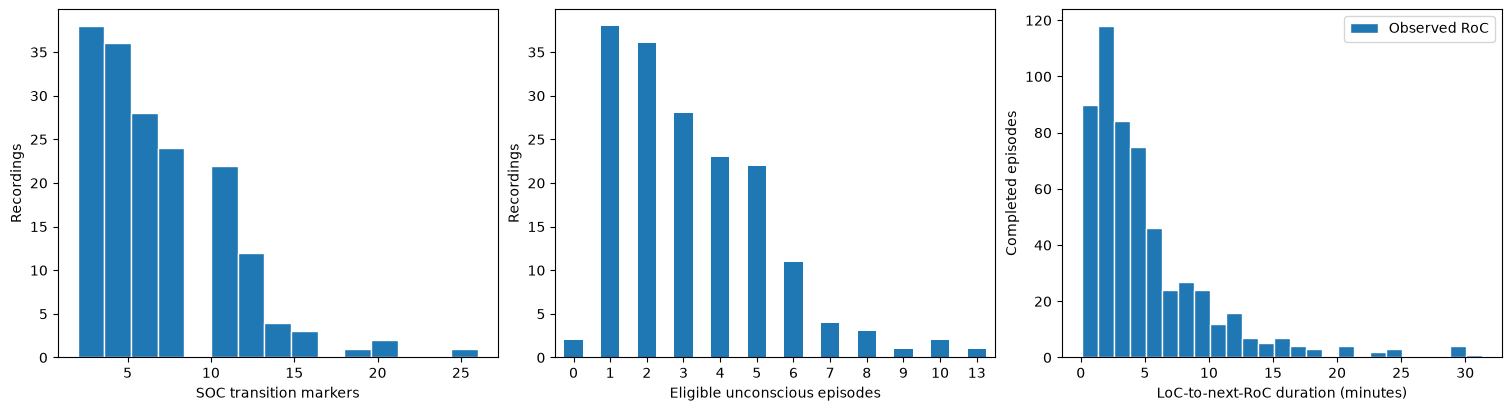

,completed_episode_minutes
count,556.000
mean,5.047
std,4.948
min,0.073
10%,1.008
25%,1.766
50%,3.399
75%,6.594
90%,11.276
95%,15.006


In [10]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    constrained_layout=True,
)

axes[0].hist(
    recordings["soc_transitions"],
    bins=15,
    edgecolor="white",
)
axes[0].set(
    xlabel="SOC transition markers",
    ylabel="Recordings",
)

episode_counts = (
    recordings["eligible_episodes"]
    .value_counts()
    .sort_index()
)
#episode_counts.plot.bar(ax=axes[1], color="#468b78")
episode_counts.plot.bar(ax=axes[1])
axes[1].set(
    xlabel="Eligible unconscious episodes",
    ylabel="Recordings",
)
axes[1].tick_params(axis="x", rotation=0)

axes[2].hist(
    completed["duration_minutes"],
    bins=25,
    edgecolor="white",
    label="Observed RoC",
)

if not censored.empty:
    axes[2].plot(
        censored["duration_minutes"],
        [0] * len(censored),
        "|",
        color="red",
        markersize=14,
        label="Censored follow-up",
    )

axes[2].set(
    xlabel="LoC-to-next-RoC duration (minutes)",
    ylabel="Completed episodes",
)
axes[2].legend()

plt.show()

display(
    completed["duration_minutes"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .to_frame(name="completed_episode_minutes")
    .round(3)
)

Finally, let's plot the Kaplan-Meier curve for our data. 

Recall that this represents $S(t) = \mathbb{P}(\text{next RoC has not occured by } t \text{ minutes after LoC})$.

The idea here is to plot to lines. A first containing the data of all 556 completed episodes. A second using all first eligible episodes of each record, along with a confidence interval. Because episodes from the same recording are not independent and might be strongly correlated, the additional curve might be of interest to see the difference between all data and independent data. Note that we assume again here that each recording comes from a different patient, which might not be exactly the case.

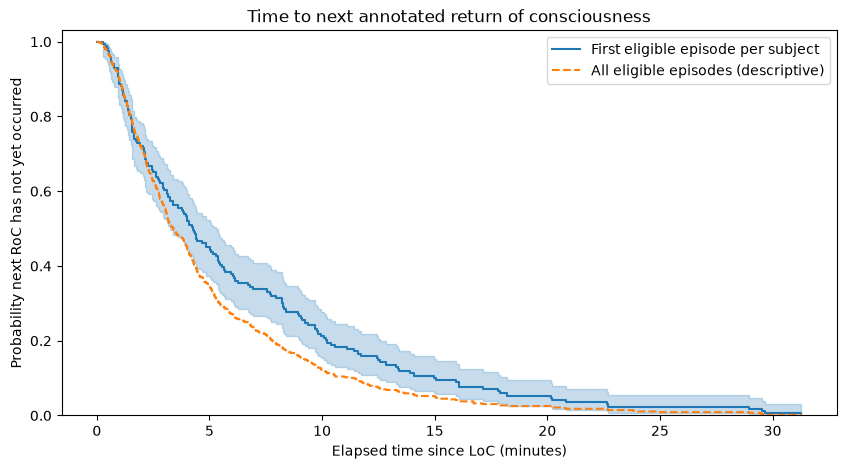

In [7]:
# Rows were appended chronologically within each recording.
first_episodes = episodes.groupby("recording_id", sort=False).head(1)

km_first = KaplanMeierFitter(
    label="First eligible episode per subject"
)
km_all = KaplanMeierFitter(
    label="All eligible episodes (descriptive)"
)

km_first.fit(
    first_episodes["duration_minutes"],
    event_observed=first_episodes["event_observed"],
)
km_all.fit(
    episodes["duration_minutes"],
    event_observed=episodes["event_observed"],
)

fig, ax = plt.subplots(figsize=(10, 5))

km_first.plot_survival_function(
    ax=ax,
    ci_show=True,
    show_censors=True,
)
km_all.plot_survival_function(
    ax=ax,
    ci_show=False,
    show_censors=True,
    linestyle="--",
)

ax.set(
    xlabel="Elapsed time since LoC (minutes)",
    ylabel="Probability next RoC has not yet occurred",
    title="Time to next annotated return of consciousness",
    ylim=(0, 1.03),
)

plt.show()

This type of probability is exactly what interests us for our study. Indeed, we will focus on the time to next RoC, and given a time $t$, output the probability of RoC occurrence. Our Random Survival Forest model will output this probability and, depending on a hyperparameter threshold $\tau$ that our model will learn, our final output will be the binary prediction of RoC occurrence by time $t$.